# Hybrid EEGNet + microstate CNN: AD vs HC classification on ds004504

Walkthrough of every phase: data → preprocessing → microstates → models → training → evaluation → figures.

**Research use only.** This classifies Alzheimer's disease (AD) vs healthy controls (HC) in a public dataset. It is not a diagnostic test.

**Research question.** Do EEG microstate features improve a compact raw-EEG CNN (EEGNet) under strict subject-wise evaluation?

**What this notebook runs and what it loads.** The full study takes hours, so this notebook runs each step on real data at a small scale, and checks the small run against the saved results. Section 5 retrains one complete repeat (5 folds, about 7 minutes on Apple MPS). Everything else in the evaluation is computed from saved predictions in `results/`.

Run from the `notebooks/` folder with the kernel from `experiments/.venv`.

In [1]:
import json, os, subprocess, sys, time, hashlib, glob
sys.path.insert(0, "../experiments")
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt, mne, numpy as np, pandas as pd, torch
from IPython.display import Image, Markdown, display
import microstates as msx
from models import MicroStateNet
from prep import CHANNELS, band_copy, find_set_file
from run_experiment import env_info, metrics
from summarize_main import corrected_t
mne.set_log_level("ERROR")
PY, BIDS, PREP, R, FIG = sys.executable, "../ds004504", "../prepared", "../results", "../figures"
print(json.dumps(env_info(), indent=1)); print("MPS available:", torch.backends.mps.is_available())

{
 "python": "3.12.16",
 "platform": "macOS-26.6.2-arm64-arm-64bit",
 "libraries": {
  "numpy": "2.5.4",
  "pandas": "3.1.0",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "mne": "1.13.2",
  "pycrostates": "0.6.1"
 }
}
MPS available: True


## 1. Data acquisition
OpenNeuro **ds004504** (Miltiadous et al., 2023; v1.0.9; CC0): resting-state, eyes-closed EEG from 88 people, 19 scalp channels. The authors have already band-pass filtered it (0.5-45 Hz) and cleaned it with ASR and ICA. We use the derivatives. The coordinator allowed a non-Kaggle data source for this project.

In [2]:
parts = pd.read_csv(f"{BIDS}/participants.tsv", sep="\t")
display(parts.groupby("Group").agg(n=("participant_id", "count"), age_mean=("Age", "mean"), mmse_mean=("MMSE", "mean")).round(1))
raw = mne.io.read_raw_eeglab(find_set_file(BIDS, "sub-001"), preload=True)
print(raw.info["nchan"], "channels,", raw.info["sfreq"], "Hz,", round(raw.times[-1]), "s")
print("Channels:", raw.ch_names)

,n,age_mean,mmse_mean
Group,,,
A,36,66.4,17.8
C,29,67.9,30.0
F,23,63.7,22.2


19 channels, 500.0 Hz, 600 s
Channels: ['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7', 'F8', 'T3', 'T4', 'T5', 'T6', 'Fz', 'Cz', 'Pz']


## 2. Preprocessing
Each subject: fixed 19-channel order, average reference, then two copies resampled to 128 Hz: **`dl`** (1-40 Hz, EEGNet input) and **`ms`** (2-20 Hz, microstates). No window is rejected. `prep.py` did this for all 88 subjects. Here we redo it for one subject and compare with the saved file.

dl shape (19, 76774) | max difference from saved file (µV): 0.0 and 0.0


,count,min,50%,max
Group,,,,
A,36.0,306.1,820.0,1281.7
C,29.0,748.5,814.6,989.9
F,23.0,479.1,699.1,1014.5


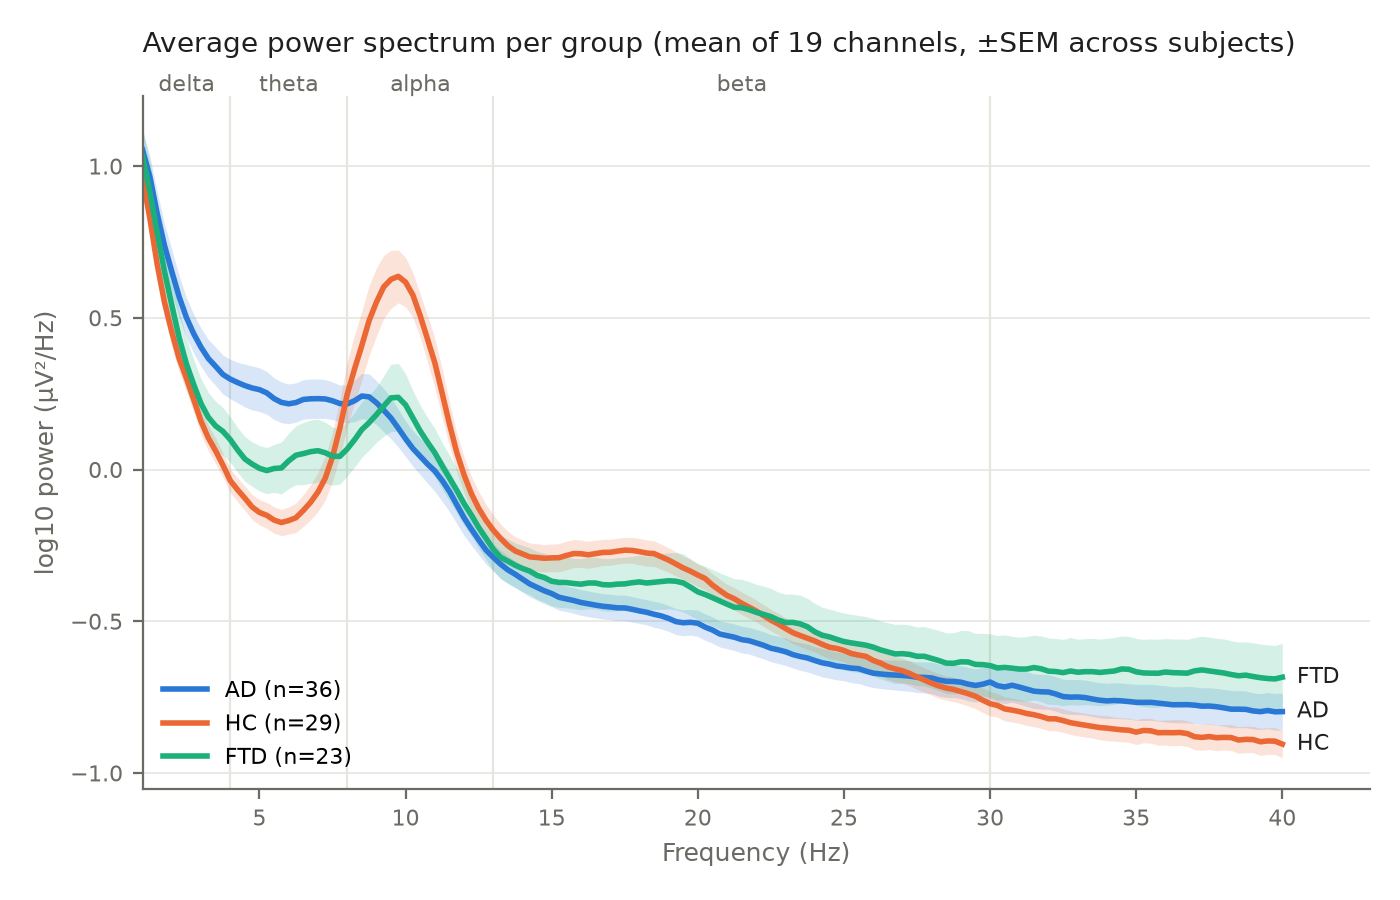

# Preprocessing report (task 03)

**Result: PASS** - 88/88 subjects prepared, 0 excluded, 1 amplitude flag(s), 0 flat-channel flag(s).




In [3]:
alias = {"T7": "T3", "T8": "T4", "P7": "T5", "P8": "T6"}
raw.rename_channels({c: alias[c] for c in raw.ch_names if c in alias})
raw.pick(CHANNELS); raw.set_eeg_reference("average", projection=False)
dl, ms_copy = band_copy(raw, 1.0, 40.0), band_copy(raw, 2.0, 20.0)
saved = np.load(f"{PREP}/sub-001.npz")
print("dl shape", dl.shape, "| max difference from saved file (µV):", np.abs(dl - saved["dl"]).max(), "and", np.abs(ms_copy - saved["ms"]).max())
subs = pd.read_csv(f"{PREP}/subjects.csv")
display(subs.groupby("Group").duration_s.describe()[["count", "min", "50%", "max"]].round(1))
display(Image(f"{FIG}/prep/psd_per_group.png", width=700))
print(open(f"{R}/prep_report.md").read().split("## Settings")[0])

## 3. Microstates
Microstates are brief, repeating scalp voltage patterns. We fit 4 maps (modified k-means, Pycrostates) on GFP peaks **from training subjects only**, then correlate every sample with each map. This gives the (4 × time) |correlation| sequence for the hybrid and 24 summary features per subject for the baselines.

Here: the real training set of repeat 3, fold 0, using the same seed as the run.

52 train / 13 test subjects; GEV 0.662; fit in 13 s
Same fold in the confirmation run log:
00:24:53 rep 3 fold 0: maps fitted (GEV 0.662), 52 train / 13 test subjects


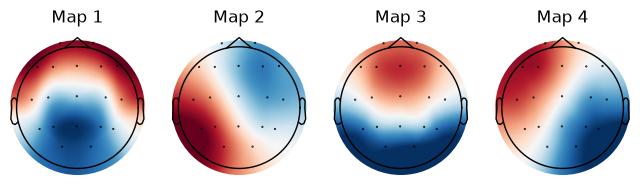

In [4]:
from sklearn.model_selection import StratifiedKFold
ad_hc = subs[subs.Group.isin(["A", "C"])].reset_index(drop=True)
names, y = ad_hc.participant_id.values, (ad_hc.Group == "A").astype(int).values
data = {s: dict(np.load(f"{PREP}/{s}.npz")) for s in names}
rep, fold = 3, 0
tr_i, te_i = list(StratifiedKFold(5, shuffle=True, random_state=rep).split(names, y))[fold]
assert not set(names[tr_i]) & set(names[te_i])  # no subject in both
seed = 100 * rep + fold
rng = np.random.default_rng(seed)
peaks = [msx.gfp_peaks(data[s]["ms"], rng=rng) for s in names[tr_i]]
t0 = time.time(); maps, gev = msx.fit_maps(peaks, CHANNELS, 128.0, seed=seed)
print(f"{len(tr_i)} train / {len(te_i)} test subjects; GEV {gev:.3f}; fit in {time.time() - t0:.0f} s")
print("Same fold in the confirmation run log:")
print([l.strip() for l in open(f"{R}/confirmation/seed0/log.txt") if "rep 3 fold 0: maps" in l][0])
info = mne.create_info(CHANNELS, 128.0, "eeg"); info.set_montage("standard_1020")
fig, ax = plt.subplots(1, 4, figsize=(8, 2.1))
for k in range(4):
    mne.viz.plot_topomap(maps[k], info, axes=ax[k], show=False, cmap="RdBu_r", contours=0); ax[k].set_title(f"Map {k + 1}")
plt.show()

Test subject sub-001 | correlation sequence (4, 76774) | 24 features


,coverage_0,coverage_1,coverage_2,coverage_3,duration_ms_0,duration_ms_1,duration_ms_2,duration_ms_3,occurrence_0,occurrence_1,occurrence_2,occurrence_3
value,0.44,0.166,0.228,0.165,39.311,19.266,25.421,18.694,11.204,8.64,8.956,8.85


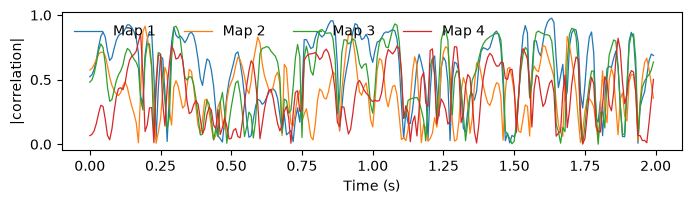

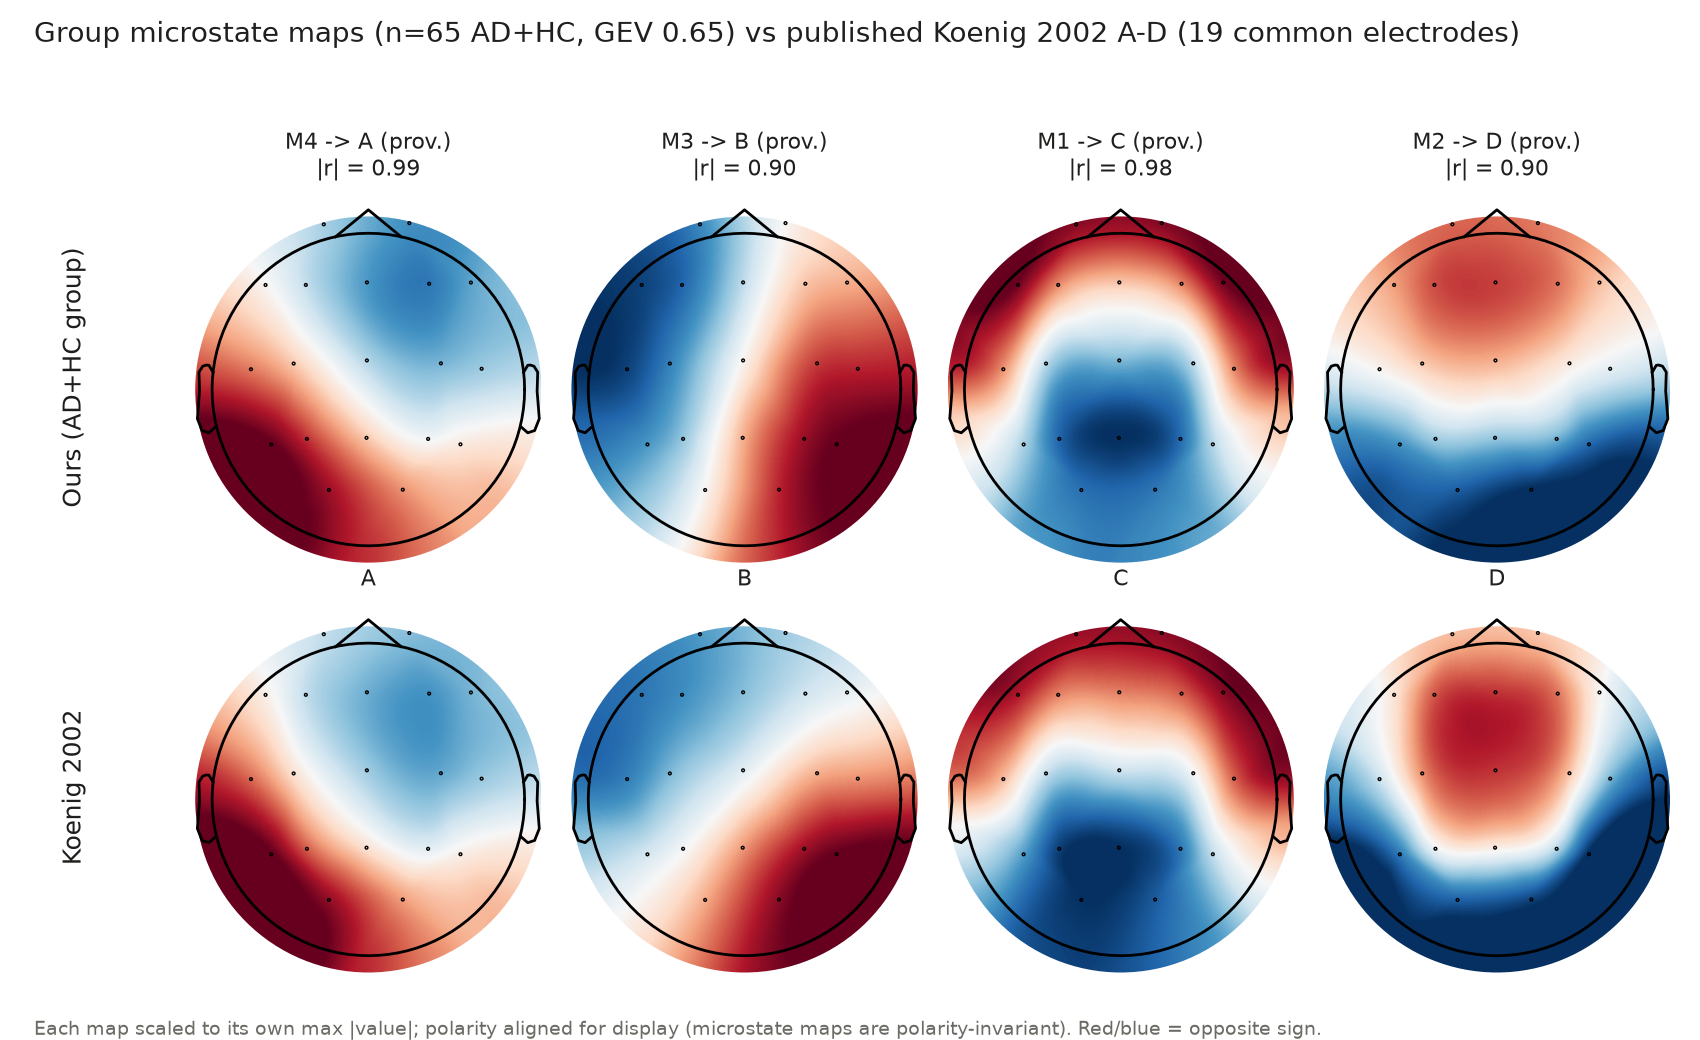

Task 04 validation: group maps vs Koenig 2002, and our code vs NeuroState-Microstates (previously released by one of the authors, used unmodified for validation). See results/microstate_validation.md.


In [5]:
s = names[te_i][0]
corr = msx.corr_sequence(data[s]["ms"], maps)
f = msx.features(corr.argmax(0), 128.0)
print("Test subject", s, "| correlation sequence", corr.shape, "|", len(f), "features")
display(pd.Series(f[:12], index=msx.FEATURE_NAMES[:12]).round(3).to_frame("value").T)
plt.figure(figsize=(8, 1.8)); plt.plot(np.arange(256) / 128, corr[:, :256].T, lw=0.9); plt.xlabel("Time (s)"); plt.ylabel("|correlation|"); plt.legend([f"Map {k + 1}" for k in range(4)], ncol=4, frameon=False); plt.show()
display(Image(f"{FIG}/microstates/group_maps_vs_koenig.png", width=700))
print("Task 04 validation: group maps vs Koenig 2002, and our code vs NeuroState-Microstates (previously released by one of the authors, used unmodified for validation). See results/microstate_validation.md.")

## 4. Models
- **A. Baseline:** 24 microstate features → logistic regression / random forest.
- **B. EEGNet** (Lawhern et al., 2018; our PyTorch re-implementation) on raw 4-s windows.
- **C. Hybrid (ours):** EEGNet branch + small 1D-CNN on the |correlation| sequence, concatenated.
- **Late fusion:** mean of the EEGNet and logistic-regression probabilities, weights 0.5/0.5 fixed in advance.

EEGNet parameters: 1922
Hybrid parameters: 8370
MicroStateNet(
  (eeg): EEGBranch(
    (net): Sequential(
      (0): Conv2d(1, 8, kernel_size=(1, 64), stride=(1, 1), padding=same, bias=False)
      (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): Conv2d(8, 16, kernel_size=(19, 1), stride=(1, 1), groups=8, bias=False)
      (3): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (4): ELU(alpha=1.0)
      (5): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
      (6): Dropout(p=0.5, inplace=False)
      (7): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=same, groups=16, bias=False)
      (8): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (9): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (10): ELU(alpha=1.0)
      (11): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
      (12): Dropout

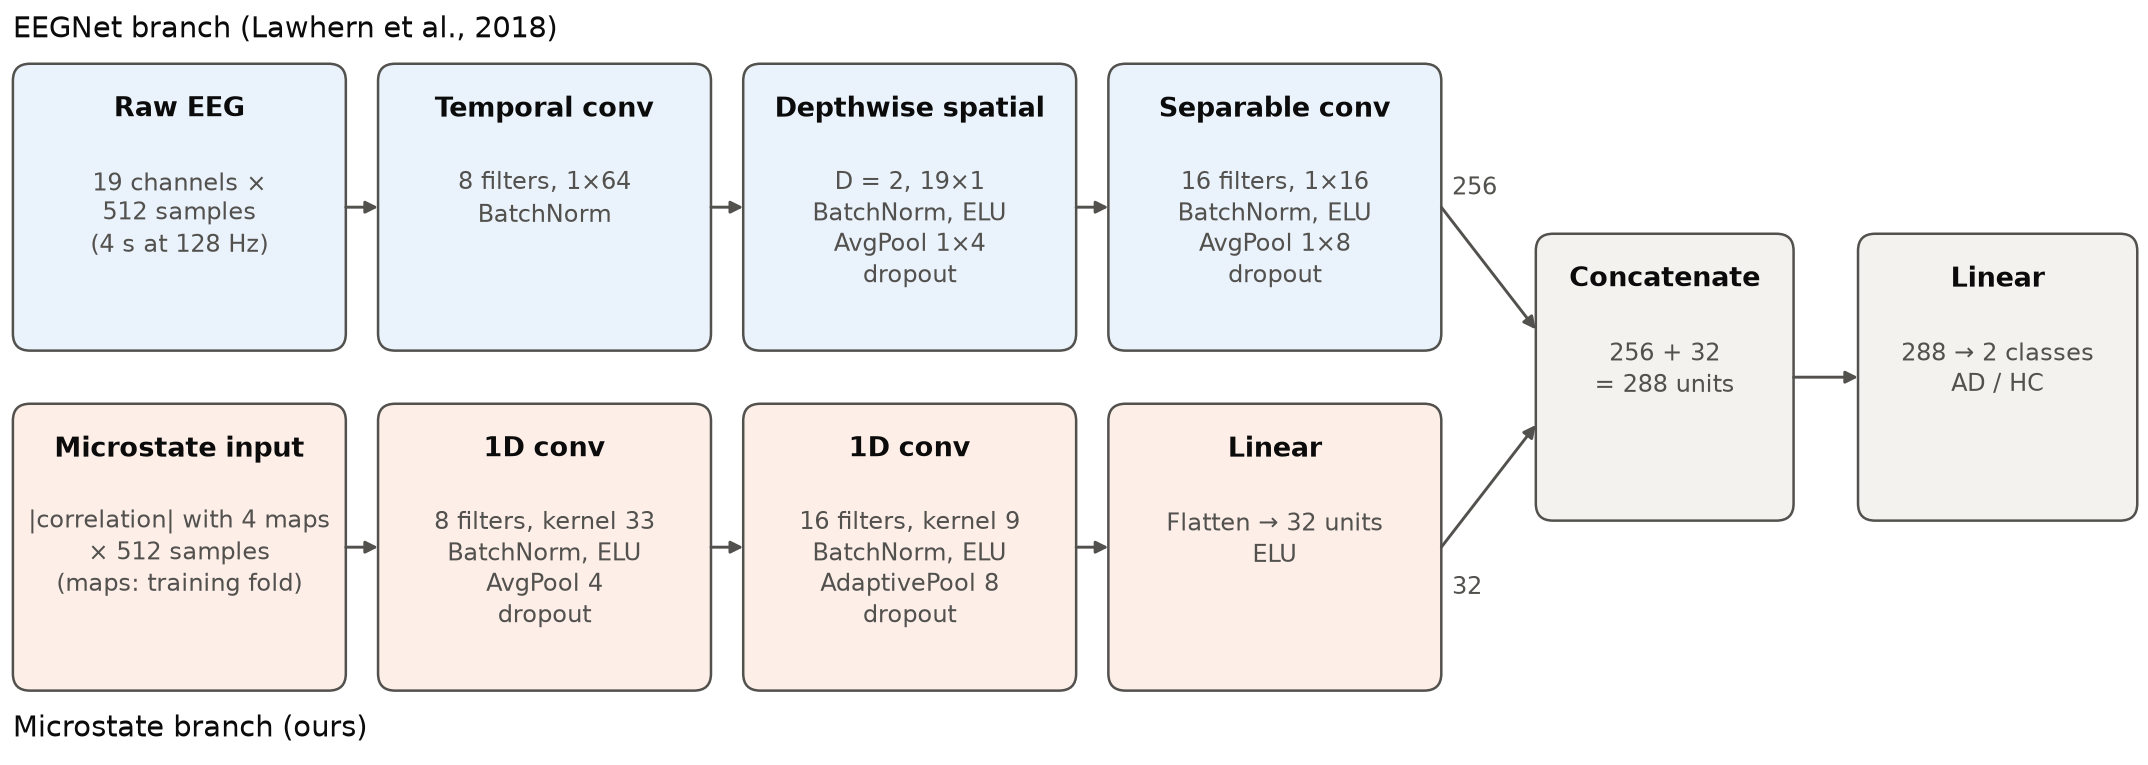

In [6]:
for use_ms, name in ((False, "EEGNet"), (True, "Hybrid")):
    net = MicroStateNet(n_chans=19, n_times=512, n_classes=2, use_ms=use_ms)
    print(name, "parameters:", sum(p.numel() for p in net.parameters()))
print(net)
out = net(torch.zeros(2, 19, 512), torch.zeros(2, 4, 512)); print("Output for 2 windows:", out.shape)
display(Image(f"{FIG}/paper/fig1_architecture.png", width=800))

## 5. Training: one full repeat, retrained and compared with the saved run
Settings: Adam (learning rate 1e-3, weight decay 1e-3), dropout 0.5, up to 40 epochs, early stopping (patience 8) on validation subjects taken from the training fold only, 64 random 4-s crops per subject per epoch, batch 64, class-weighted loss. A subject's score is the mean of its window probabilities; threshold 0.5.

This retrains repeat 3 with seed offset 0, into its own folder, and compares with `results/confirmation/seed0`. The confirmation results themselves are not touched.

In [7]:
out = f"{R}/notebook_repeat3"
cmd = [PY, "-W", "ignore", "../experiments/run_experiment.py", "--prep", PREP, "--out", out, "--first-repeat", "3", "--repeats", "1",
       "--skip-leak", "--device", "mps", "--groups", "A", "C", "--seed-offset", "0"]
print(" ".join(cmd))
if not os.path.exists(f"{out}/results.json"):
    os.makedirs(out, exist_ok=True); t0 = time.time()
    with open(f"{out}/log.txt", "w") as fh: subprocess.run(cmd, stdout=fh, stderr=subprocess.STDOUT, check=True)
    print(f"Trained in {(time.time() - t0) / 60:.1f} min")
print("".join(l for l in open(f"{out}/log.txt") if "rep 3 fold 0" in l or "epochs" in l or "bal.acc" in l)[:900])
new = pd.read_csv(f"{out}/oof_predictions.csv")
old = pd.read_csv(f"{R}/confirmation/seed0/oof_predictions.csv"); old = old[old.repeat == 3]
key = ["repeat", "fold", "model", "subject"]
m = new.merge(old, on=key, suffixes=("_new", "_saved"), validate="one_to_one"); assert len(m) == len(old) == len(new)
print(f"{len(m)} predictions compared. Largest probability difference per model:")
print(m.assign(d=(m.prob_new - m.prob_saved).abs()).groupby("model").d.max())

/Users/nawaf/Desktop/Neurostate/experiments/.venv/bin/python -W ignore ../experiments/run_experiment.py --prep ../prepared --out ../results/notebook_repeat3 --first-repeat 3 --repeats 1 --skip-leak --device mps --groups A C --seed-offset 0


Trained in 6.7 min
11:22:20 rep 3 fold 0: maps fitted (GEV 0.662), 52 train / 13 test subjects
11:22:46    eegnet: trained 11 epochs
11:23:15    hybrid: trained 13 epochs
11:23:15    baseline_logreg  bal.acc 0.875
11:23:15    baseline_rf      bal.acc 0.738
11:23:15    eegnet           bal.acc 0.900
11:23:15    hybrid           bal.acc 0.812
11:24:13    eegnet: trained 20 epochs
11:24:42    hybrid: trained 13 epochs
11:24:42    baseline_logreg  bal.acc 1.000
11:24:42    baseline_rf      bal.acc 0.845
11:24:42    eegnet           bal.acc 1.000
11:24:42    hybrid           bal.acc 0.917
11:25:25    eegnet: trained 12 epochs
11:25:53    hybrid: trained 12 epochs
11:25:53    baseline_logreg  bal.acc 0.833
11:25:53    baseline_rf      bal.acc 0.845
11:25:53    eegnet           bal.acc 0.833
11:25:53    hybrid           bal.acc 0.750
11:26:45    eegnet: trained 14 epochs
11:27:16    hybrid: trained 13 epochs
11:2
260 predictions compared. Largest probability difference per model:
model
baseli

The whole study, from `experiments/`. Results are in `results/`, each run with its settings, seeds, library versions and runtime in `results.json`.

```bash
python prep.py --bids ../ds004504 --out ../prepared
python run_experiment.py --prep ../prepared --out ../results/main_AD_vs_HC --repeats 3                 # Task 05, includes the leakage demo
for k in 0 1 2 3 4; do python run_experiment.py --prep ../prepared --out ../results/confirmation/seed$k --repeats 3 --first-repeat 3 --skip-leak --device mps --groups A C --seed-offset $((1000*k)); done
python confirmation.py --runs ../results/confirmation/seed{0..4} --earlier-runs ../results/improve_mps_rerun ../results/improve_seed{1..4}
python make_figures.py
```

## 6. Evaluation
**Preregistered confirmation run** (`results/confirmation/PREREGISTERED.md`): models and analysis fixed before the run; new splits (repeat seeds 3-5, 15 folds); 5 network seeds; nothing tuned. The subjects are the same 65 as in all earlier comparisons, so this is not an independent test set.

The cell below recomputes the ensembles, fusion and fold metrics from the 5 raw seed runs, and checks them against the saved summary.

In [8]:
runs = [pd.read_csv(f"{R}/confirmation/seed{k}/oof_predictions.csv") for k in range(5)]
ens = lambda model: pd.concat([r[r.model == model] for r in runs]).groupby(["repeat", "fold", "subject", "label"]).prob.mean().reset_index()
E, H = ens("eegnet"), ens("hybrid")
base = lambda model: runs[0][runs[0].model == model][["repeat", "fold", "subject", "label", "prob"]]
LR, RF = base("baseline_logreg"), base("baseline_rf")
F = E.merge(LR, on=["repeat", "fold", "subject", "label"], suffixes=("", "_lr")); F["prob"] = 0.5 * F.prob + 0.5 * F.prob_lr
table = {"Late fusion": F, "Hybrid ensemble": H, "EEGNet ensemble": E, "Logistic regression": LR, "Random forest": RF}
fold_scores = {n: pd.DataFrame([{"repeat": r, "fold": f, **metrics(g.label.values, g.prob.values)} for (r, f), g in d.groupby(["repeat", "fold"])]) for n, d in table.items()}
display(pd.DataFrame({n: {k: f"{d[k].mean():.3f} ± {d[k].std():.3f}" for k in ("balanced_accuracy", "auc", "f1")} for n, d in fold_scores.items()}).T)
saved = json.load(open(f"{R}/confirmation/results.json"))["models"]
key = dict(zip(table, ("fusion_eegnet_ens5_logreg", "hybrid_ens5", "eegnet_ens5", "baseline_logreg", "baseline_rf")))
print("Largest difference from results/confirmation/results.json:", max(abs(fold_scores[n].balanced_accuracy.mean() - saved[key[n]]["balanced_accuracy"]["mean"]) for n in table))
rows = []
for a, b in (("Late fusion", "EEGNet ensemble"), ("Hybrid ensemble", "EEGNet ensemble"), ("Late fusion", "Hybrid ensemble")):
    d = fold_scores[a].balanced_accuracy.values - fold_scores[b].balanced_accuracy.values
    rows.append({"comparison": f"{a} vs {b}", "mean difference": round(d.mean(), 3), "corrected p": round(corrected_t(d, 52, 13)[1], 3)})
display(pd.DataFrame(rows))

,balanced_accuracy,auc,f1
Late fusion,0.869 ± 0.083,0.928 ± 0.077,0.853 ± 0.110
Hybrid ensemble,0.791 ± 0.082,0.901 ± 0.105,0.761 ± 0.124
EEGNet ensemble,0.816 ± 0.104,0.920 ± 0.088,0.803 ± 0.127
Logistic regression,0.831 ± 0.094,0.917 ± 0.066,0.828 ± 0.102
Random forest,0.812 ± 0.075,0.880 ± 0.086,0.812 ± 0.087


Largest difference from results/confirmation/results.json: 0.0


,comparison,mean difference,corrected p
0,Late fusion vs EEGNet ensemble,0.053,0.320
1,Hybrid ensemble vs EEGNet ensemble,-0.025,0.591
2,Late fusion vs Hybrid ensemble,0.078,0.116


No preregistered comparison reaches p < 0.05. The hybrid does not beat EEGNet, and late fusion's higher mean is not shown to be a real improvement over either network ensemble.

In [9]:
display(Markdown(open(f"{FIG}/paper/table1_main_results.md").read()))
display(Markdown(open(f"{FIG}/paper/table2_comparisons.md").read()))
display(Markdown(open(f"{FIG}/paper/table5_three_class.md").read()))
leak = json.load(open(f"{R}/main_AD_vs_HC/results.json"))["leakage_demo_eegnet_window_split"]
print("Leakage demo, EEGNet, random window split: balanced accuracy", round(leak["balanced_accuracy"], 3), "(same people in train and test)")

**Preregistered confirmation run: AD vs HC, 65 subjects, 5-fold subject-wise CV with repeat seeds 3-5 (15 folds), threshold 0.5. Mean ± SD over folds. The subjects are those of all earlier comparisons, on new splits: not an independent test set.**

| Model | Balanced acc. | AUC | F1 | Pooled AUC [95% CI] | Sens. (pooled) | Spec. (pooled) |
|---|---|---|---|---|---|---|
| Late fusion (EEGNet ens. + LR) | 0.869 ± 0.083 | 0.928 ± 0.077 | 0.853 ± 0.110 | 0.906 [0.833, 0.968] | 0.796 | 0.943 |
| Hybrid ensemble | 0.791 ± 0.082 | 0.901 ± 0.105 | 0.761 ± 0.124 | 0.863 [0.776, 0.936] | 0.694 | 0.885 |
| EEGNet ensemble | 0.816 ± 0.104 | 0.920 ± 0.088 | 0.803 ± 0.127 | 0.877 [0.793, 0.944] | 0.759 | 0.874 |
| Logistic regression (baseline) | 0.831 ± 0.094 | 0.917 ± 0.066 | 0.828 ± 0.102 | 0.904 [0.831, 0.962] | 0.787 | 0.874 |
| Random forest (baseline) | 0.812 ± 0.075 | 0.880 ± 0.086 | 0.812 ± 0.087 | 0.868 [0.769, 0.946] | 0.769 | 0.862 |


**Preregistered comparisons, paired over 15 folds. p = Nadeau-Bengio corrected resampled t-test, two-sided, unadjusted (3 primary and 6 secondary tests). No comparison reaches p < 0.05.**

| Comparison | Metric | Mean diff. (SD) | Better / tied / worse | p |
|---|---|---|---|---|
| Late fusion vs EEGNet | Balanced acc. (primary) | +0.053 (0.091) | 10 / 2 / 3 | 0.320 |
| Late fusion vs EEGNet | AUC | +0.008 (0.048) | 5 / 5 / 5 | 0.768 |
| Late fusion vs EEGNet | F1 | +0.050 (0.095) | 9 / 2 / 4 | 0.370 |
| Hybrid vs EEGNet | Balanced acc. (primary) | -0.025 (0.080) | 3 / 5 / 7 | 0.591 |
| Hybrid vs EEGNet | AUC | -0.019 (0.041) | 3 / 4 / 8 | 0.425 |
| Hybrid vs EEGNet | F1 | -0.042 (0.102) | 2 / 5 / 8 | 0.474 |
| Late fusion vs Hybrid | Balanced acc. (primary) | +0.078 (0.083) | 10 / 5 / 0 | 0.116 |
| Late fusion vs Hybrid | AUC | +0.027 (0.052) | 7 / 5 / 3 | 0.374 |
| Late fusion vs Hybrid | F1 | +0.092 (0.110) | 10 / 5 / 0 | 0.159 |


**Secondary task: AD vs FTD vs HC, 5-fold subject-wise CV × 3 (repeat seeds 0-2), chance = 0.333. The full cohort is the main result and the sub-086 exclusion is a sensitivity analysis. Effect = same test subjects, sub-086 removed from training and map fitting minus kept; p = corrected resampled t-test.**

| Model | Bal. acc. (n = 88) | Macro-F1 | Macro AUC | Bal. acc. without sub-086 (n = 87) | Effect of removal (p) |
|---|---|---|---|---|---|
| Logistic regression (baseline) | 0.554 ± 0.102 | 0.534 ± 0.099 | 0.745 ± 0.052 | 0.594 ± 0.093 | +0.037 (0.19) |
| Random forest (baseline) | 0.579 ± 0.087 | 0.565 ± 0.090 | 0.746 ± 0.055 | 0.576 ± 0.070 | -0.008 (0.87) |
| EEGNet ensemble | 0.572 ± 0.084 | 0.542 ± 0.097 | 0.763 ± 0.065 | 0.572 ± 0.070 | +0.006 (0.90) |
| Hybrid ensemble | 0.569 ± 0.100 | 0.540 ± 0.099 | 0.763 ± 0.084 | 0.580 ± 0.116 | +0.013 (0.75) |


Leakage demo, EEGNet, random window split: balanced accuracy 0.956 (same people in train and test)


## 7. Figures
All paper figures and tables come from `experiments/make_figures.py`. Rerunning it must leave every file unchanged.

25 files; unchanged after rerun: True


**fig2_roc**

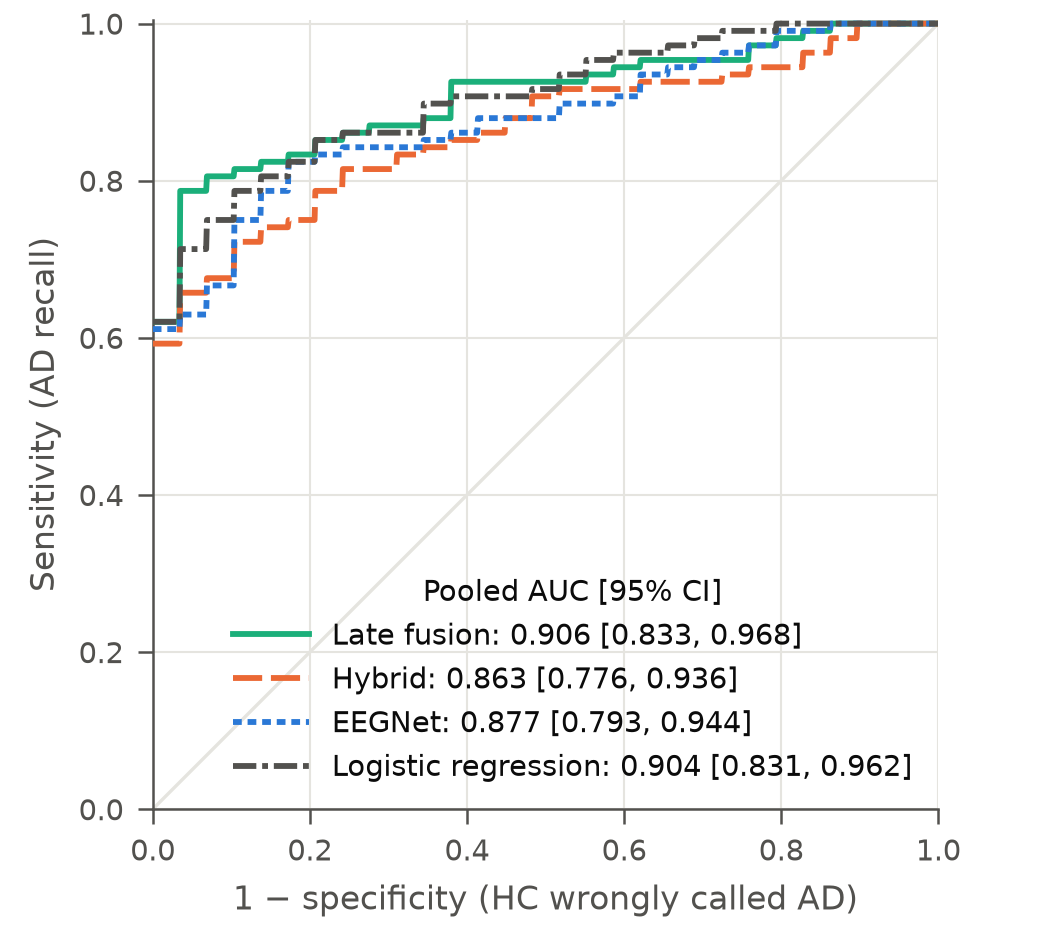

**fig3_confusion**

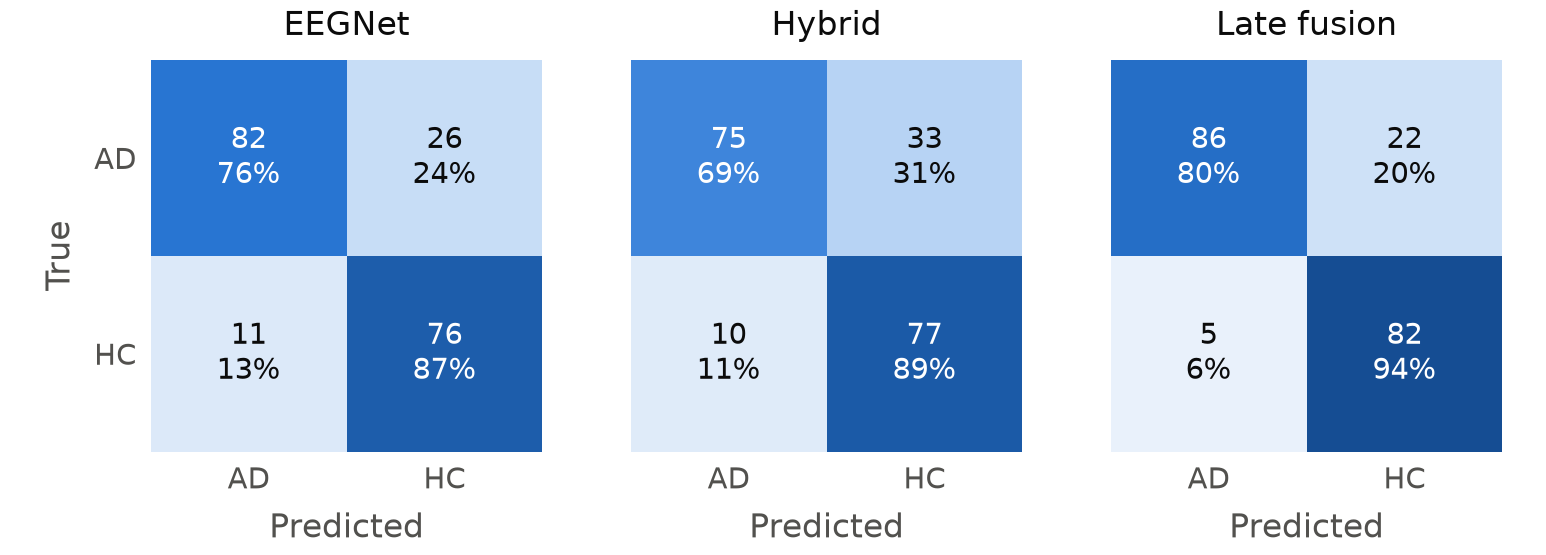

**fig4_leakage**

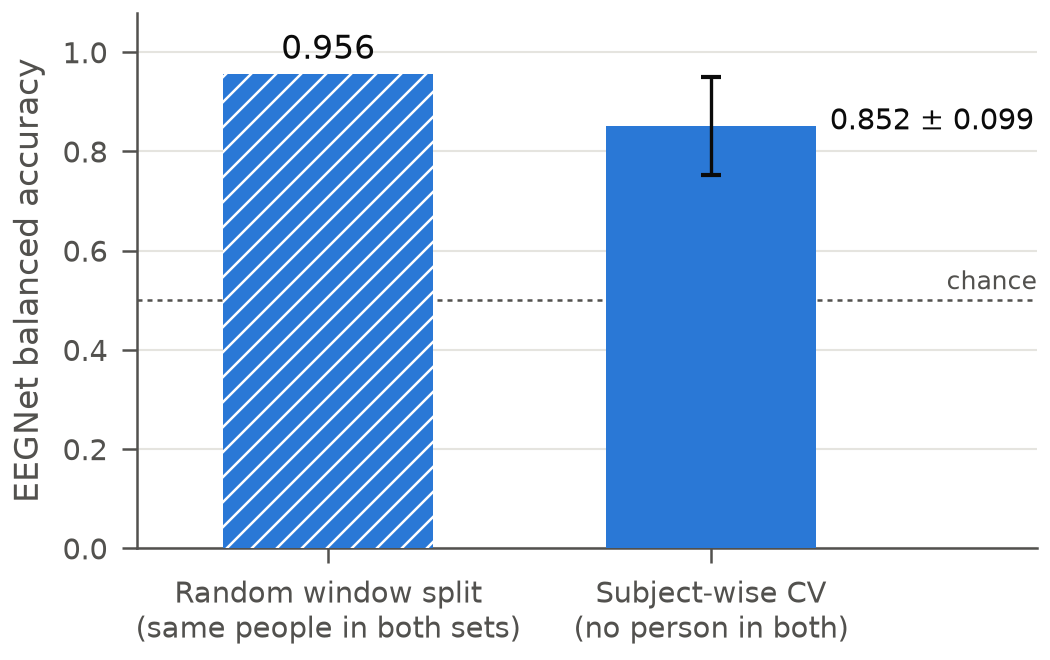

**fig5_microstate_maps**

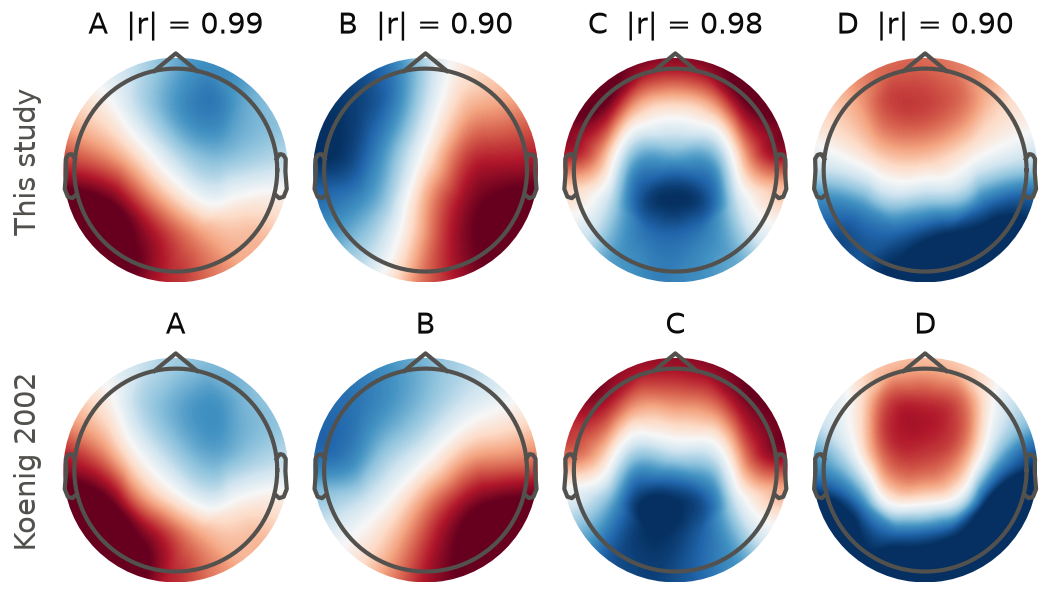

**fig6_microstate_features**

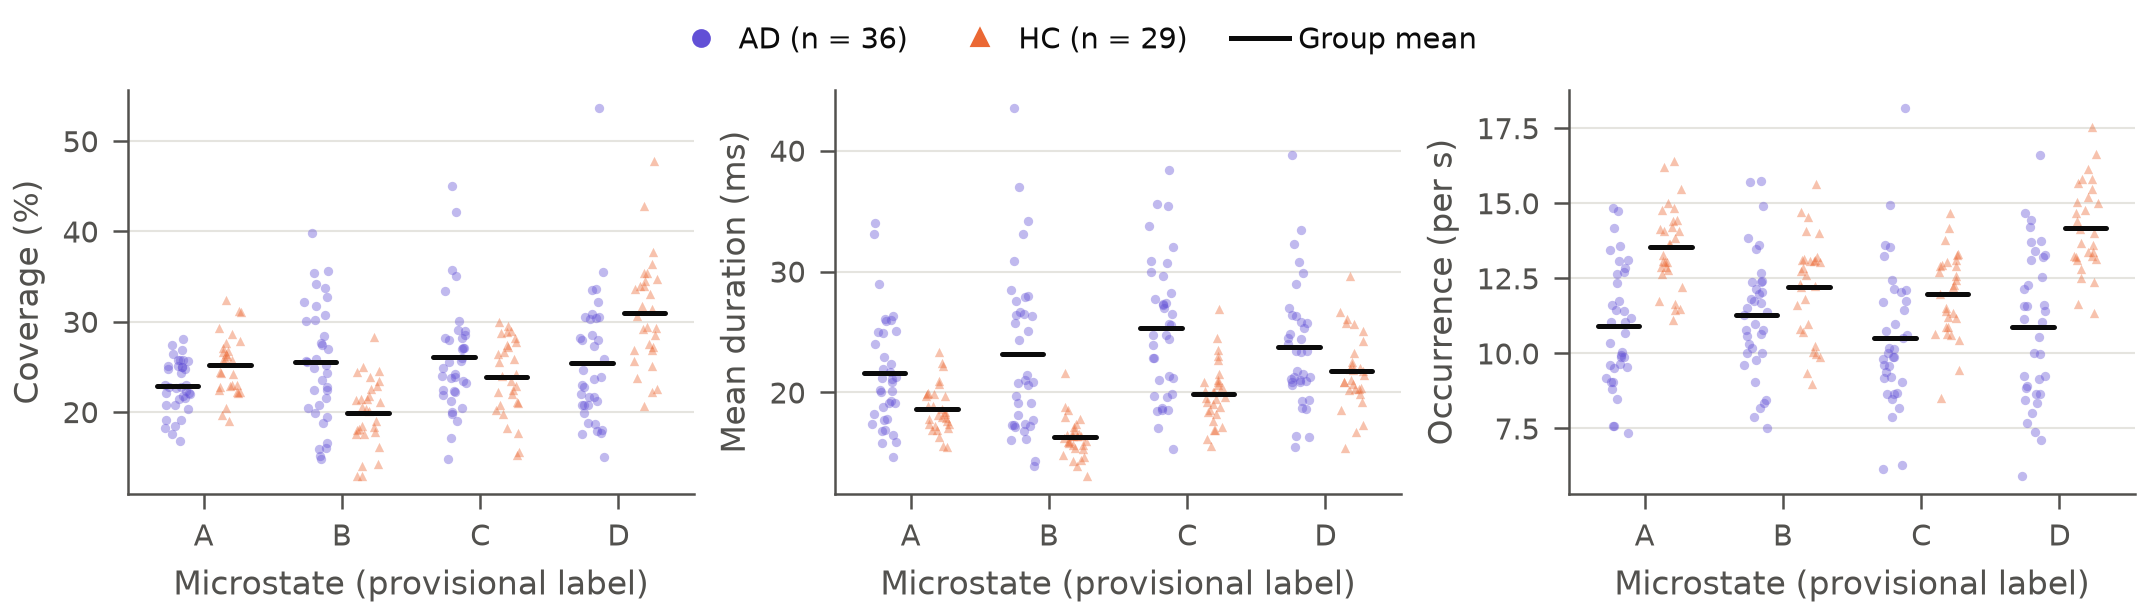

In [10]:
digest = lambda: {os.path.basename(p): hashlib.sha256(open(p, "rb").read()).hexdigest() for p in sorted(glob.glob(f"{FIG}/paper/*"))}
before = digest()
subprocess.run([PY, "-W", "ignore", "make_figures.py"], cwd="../experiments", check=True, env={**os.environ, "PYTHONDONTWRITEBYTECODE": "1"})
print(len(before), "files; unchanged after rerun:", before == digest())
for n in ("fig2_roc", "fig3_confusion", "fig4_leakage", "fig5_microstate_maps", "fig6_microstate_features"):
    display(Markdown(f"**{n}**")); display(Image(f"{FIG}/paper/{n}.png", width=620))